# Stage-2 RLVR Post-Training: Policy Parameterization, Verifiable Rewards, and Dr. GRPO Optimization

This notebook examines the mathematical pipeline implemented in `models/grpo_policy_wrapper.py` (`DINOGRPOPolicyWrapper`) and `losses/dr_grpo_loss.py` (`DrGRPOLoss`):
1. **Bernoulli Policy Parameterization $\pi_\theta(\mathbf{a}|I)$**: Combining standardized last-layer `[CLS]` attention, residual MLP gating logits, and spectral-spatial TokenCut diffusion.
2. **Group Rollout Sampling ($G=8$)**: Sampling binary patch selection masks $\mathbf{a}^{(1)}, \dots, \mathbf{a}^{(G)} \in \{0, 1\}^{196}$ per image.
3. **Self-Supervised Verifiable Rewards (`self_supervised_v1`)**:
   - $R_{\text{equiv}}$ (*Geometric Equivariance IoU*, weight $0.45$)
   - $R_{\text{compact}}$ (*TokenCut Spectral Association + 2D Total Variation Smoothness*, weight $0.35$)
   - $R_{\text{sparsity}}$ (*Target Sparsity Ratio Prior* $\rho_{\text{target}}=0.35$, weight $0.20$)
4. **Unbiased Group-Relative Advantage (`dr_grpo` vs. `rank_grpo`) and DAPO Asymmetric Clip-Higher Objective**.

In [1]:
import os, sys, math, glob
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

if os.path.exists("/Users/KhangDS/Programing/HCMUS_Code/ComputerVision_code/DINOv1"):
    os.chdir("/Users/KhangDS/Programing/HCMUS_Code/ComputerVision_code/DINOv1")
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())

from core.registry import MODULES
import models
import losses
from train_grpo_post import resolve_checkpoint_path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams["figure.dpi"] = 130

rop_grpo_ckpt = resolve_checkpoint_path("cp/checkpoints_rop_grpo/checkpoint0190.pth")
policy_wrapper = MODULES.build({
    "type": "DINOGRPOPolicyWrapper",
    "arch": "auto",
    "patch_size": 16,
    "pretrained_weights": rop_grpo_ckpt,
    "num_unfrozen_blocks": 2,
    "target_sparsity": 0.35,
}).to(device).eval()

grpo_loss_fn = MODULES.build({
    "type": "DrGRPOLoss",
    "group_size": 8,
    "eps_low": 0.20,
    "eps_high": 0.28,
    "beta_kl": 0.04,
    "adv_type": "dr_grpo",
    "reward_mode": "self_supervised_v1",
    "target_sparsity": 0.35,
})

param_stats = policy_wrapper.configure_trainable_parameters(num_unfrozen_blocks=2)
print(f"Loaded DINOGRPOPolicyWrapper ({policy_wrapper.arch}) from: {rop_grpo_ckpt}")
print(f"Trainable Parameters: {param_stats['trainable_params']:,} / {param_stats['total_params']:,} ({100*param_stats['trainable_params']/param_stats['total_params']:.2f}%)")

Loaded DINOGRPOPolicyWrapper (vit_small_sparse_rope) from: cp/checkpoints_rop_grpo/checkpoint0190.pth
Trainable Parameters: 3,587,521 / 43,369,153 (8.27%)


## 1. Policy Distribution Construction $\pi_\theta(\mathbf{a}|I)$
Given an input image $I \in \mathbb{R}^{3 \times 224 \times 224}$ partitioned into $N = 14 \times 14 = 196$ patches:
1. **Mean Multi-Head `[CLS]` Attention**:
   $$\bar{a}_p = \frac{1}{H}\sum_{h=1}^H A^{(L)}_{h, \text{CLS}, p}, \qquad \hat{a}_p = \frac{\bar{a}_p - \mu_{\bar{a}}}{\sigma_{\bar{a}} + \epsilon}$$
2. **Sparsity Prior Bias & Residual Policy Gate $g_\phi(\mathbf{z}_p)$**:
   $$b_{\text{sparsity}} = \log\!\left(\frac{\rho_{\text{target}}}{1 - \rho_{\text{target}}}\right) \approx -0.619, \qquad \ell_p^{\text{ref}} = \gamma \hat{a}_p^{\text{ref}} + b_{\text{sparsity}}$$
   $$\ell_p^{\theta} = 0.55\big(\gamma \hat{a}_p^{\theta} + b_{\text{sparsity}}\big) + 0.45\big(g_\phi(\mathbf{z}_p) + 1.35\,\hat{s}_p + b_{\text{sparsity}}\big), \qquad p_p^{\theta} = \sigma(\ell_p^{\theta}) \in (0, 1)^{196}$$

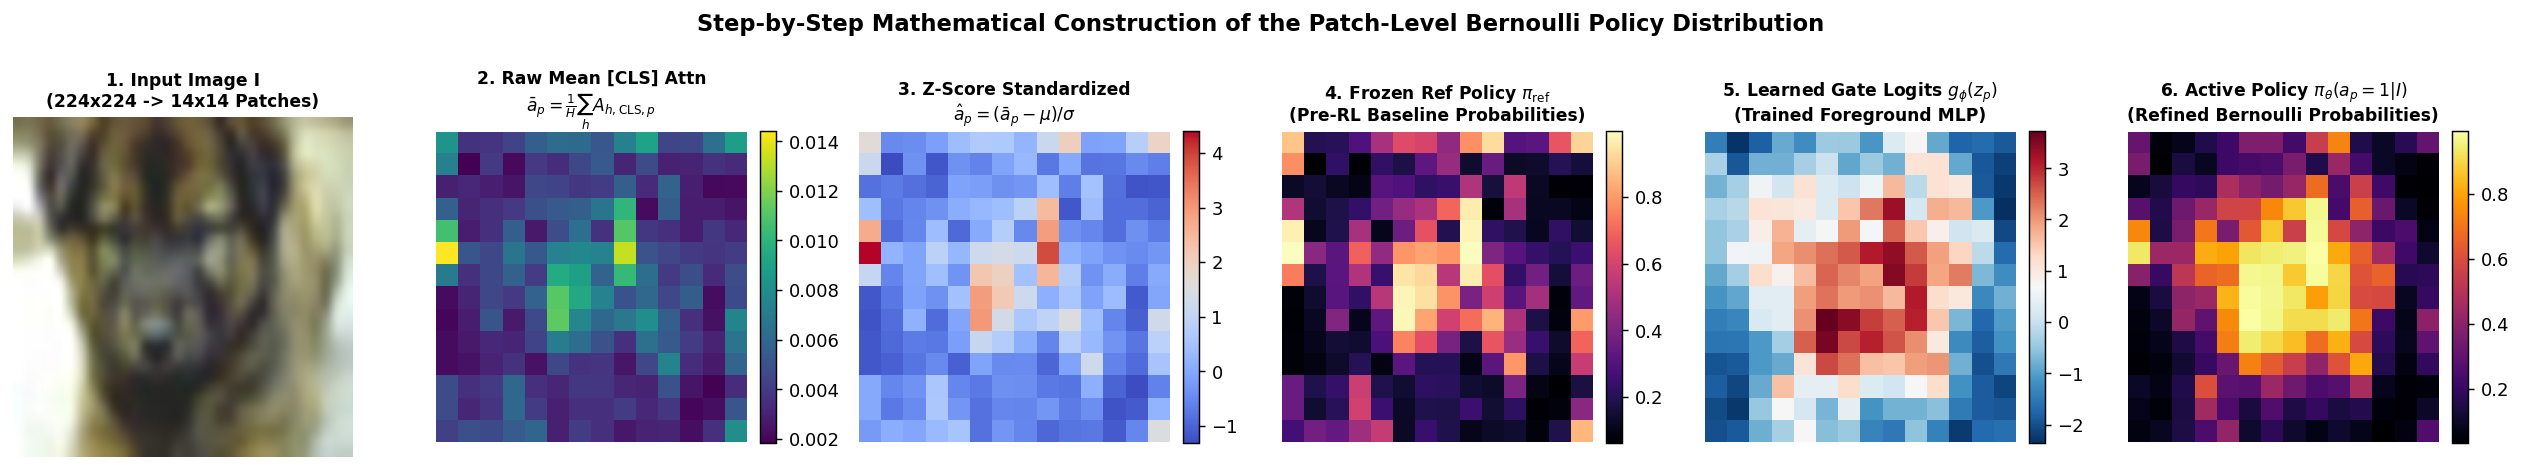

In [2]:
dog_files = sorted(glob.glob("data/cifar10/val/dog/*.png"))
img_path_demo = dog_files[4] if len(dog_files) > 4 else dog_files[0]

pil_img = Image.open(img_path_demo).convert("RGB").resize((224, 224), Image.BICUBIC)
tf_eval = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])
x_in = tf_eval(pil_img).unsqueeze(0).to(device)

with torch.no_grad():
    out_dict = policy_wrapper.forward_policy_and_ref(x_in, compute_equivariant=True)
    last_attn = out_dict["last_attn"]
    patch_feats = out_dict["patch_features"]
    policy_probs = out_dict["policy_probs"]
    ref_probs = out_dict["ref_probs"]
    equiv_probs = out_dict["equivariant_probs"]

    cls_attn_mean = last_attn[:, :, 0, 1:].mean(dim=1)
    attn_z = (cls_attn_mean - cls_attn_mean.mean(dim=-1, keepdim=True)) / (cls_attn_mean.std(dim=-1, keepdim=True) + 1e-6)
    gate_logits = policy_wrapper.policy_gate(patch_feats).squeeze(-1)

fig, axes = plt.subplots(1, 6, figsize=(19.5, 3.4))

axes[0].imshow(pil_img)
axes[0].set_title("1. Input Image I\n(224x224 -> 14x14 Patches)", fontweight="bold", fontsize=9.5)
axes[0].axis("off")

steps_vis = [
    (cls_attn_mean[0].view(14, 14).cpu().numpy(), "viridis", "2. Raw Mean [CLS] Attn\n$\\bar{a}_p = \\frac{1}{H}\\sum_h A_{h,\\mathrm{CLS},p}$"),
    (attn_z[0].view(14, 14).cpu().numpy(), "coolwarm", "3. Z-Score Standardized\n$\\hat{a}_p = (\\bar{a}_p - \\mu)/\\sigma$"),
    (ref_probs[0].view(14, 14).cpu().numpy(), "magma", "4. Frozen Ref Policy $\\pi_{\\mathrm{ref}}$\n(Pre-RL Baseline Probabilities)"),
    (gate_logits[0].view(14, 14).cpu().numpy(), "RdBu_r", "5. Learned Gate Logits $g_\\phi(z_p)$\n(Trained Foreground MLP)"),
    (policy_probs[0].view(14, 14).cpu().numpy(), "inferno", "6. Active Policy $\\pi_\\theta(a_p=1|I)$\n(Refined Bernoulli Probabilities)"),
]

for ax, (arr2d, cmap_name, title_str) in zip(axes[1:], steps_vis):
    im = ax.imshow(arr2d, cmap=cmap_name)
    ax.set_title(title_str, fontweight="bold", fontsize=9.5)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Step-by-Step Mathematical Construction of the Patch-Level Bernoulli Policy Distribution", fontsize=12.5, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

## 2. Verifiable Reward Decomposition (`self_supervised_v1`)
Each sampled binary mask $\mathbf{a}^{(g)} \in \{0, 1\}^{196}$ is scored by three deterministic, label-free reward terms:

1. **Geometric Equivariance IoU ($w_{\text{eq}} = 0.45$)**:
   $$\mathbf{m}_{\text{eq}} = \text{Top-}k_{\text{fg}}\!\Big(T^{-1}\big(\pi_\theta(T(I))\big)\Big), \qquad R_{\text{equiv}}(\mathbf{a}^{(g)}, I) = \frac{\sum_{p=1}^N a_p^{(g)} m_{\text{eq}, p}}{\sum_{p=1}^N \big(a_p^{(g)} + m_{\text{eq}, p} - a_p^{(g)} m_{\text{eq}, p}\big) + \epsilon}$$

2. **TokenCut Spectral & 2D Spatial Compactness ($w_{\text{comp}} = 0.35$)**:
   $$W_{pq} = \max(0, \hat{\mathbf{z}}_p^\top \hat{\mathbf{z}}_q), \qquad R_{\text{ncut}}(\mathbf{a}^{(g)}) = \frac{1}{2}\!\left(\frac{{\mathbf{a}^{(g)}}^\top \mathbf{W} \mathbf{a}^{(g)} - {\mathbf{a}^{(g)}}^\top \mathbf{W} (\mathbf{1} - \mathbf{a}^{(g)})}{{\mathbf{a}^{(g)}}^\top \mathbf{W} \mathbf{1} + \epsilon} + 1\right)$$
   $$R_{\text{TV}}(\mathbf{a}^{(g)}) = 1 - \frac{1}{2}\Big(\|\nabla_H \mathbf{a}_{2\text{D}}^{(g)}\|_1 + \|\nabla_W \mathbf{a}_{2\text{D}}^{(g)}\|_1\Big), \qquad R_{\text{compact}}(\mathbf{a}^{(g)}) = 0.65\, R_{\text{ncut}}(\mathbf{a}^{(g)}) + 0.35\, R_{\text{TV}}(\mathbf{a}^{(g)})$$

3. **Target Sparsity Ratio Prior ($w_{\text{spar}} = 0.20$)**:
   $$R_{\text{sparsity}}(\mathbf{a}^{(g)}) = \max\!\left(0,\; 1 - \left|\frac{\bar{a}^{(g)} - \rho_{\text{target}}}{\max(\rho_{\text{target}}, 1-\rho_{\text{target}})}\right|^{1.5}\right)$$

4. **Combined Verifiable Reward**:
   $$R(\mathbf{a}^{(g)}, I) = 0.45\, R_{\text{equiv}}(\mathbf{a}^{(g)}, I) + 0.35\, R_{\text{compact}}(\mathbf{a}^{(g)}, I) + 0.20\, R_{\text{sparsity}}(\mathbf{a}^{(g)})$$

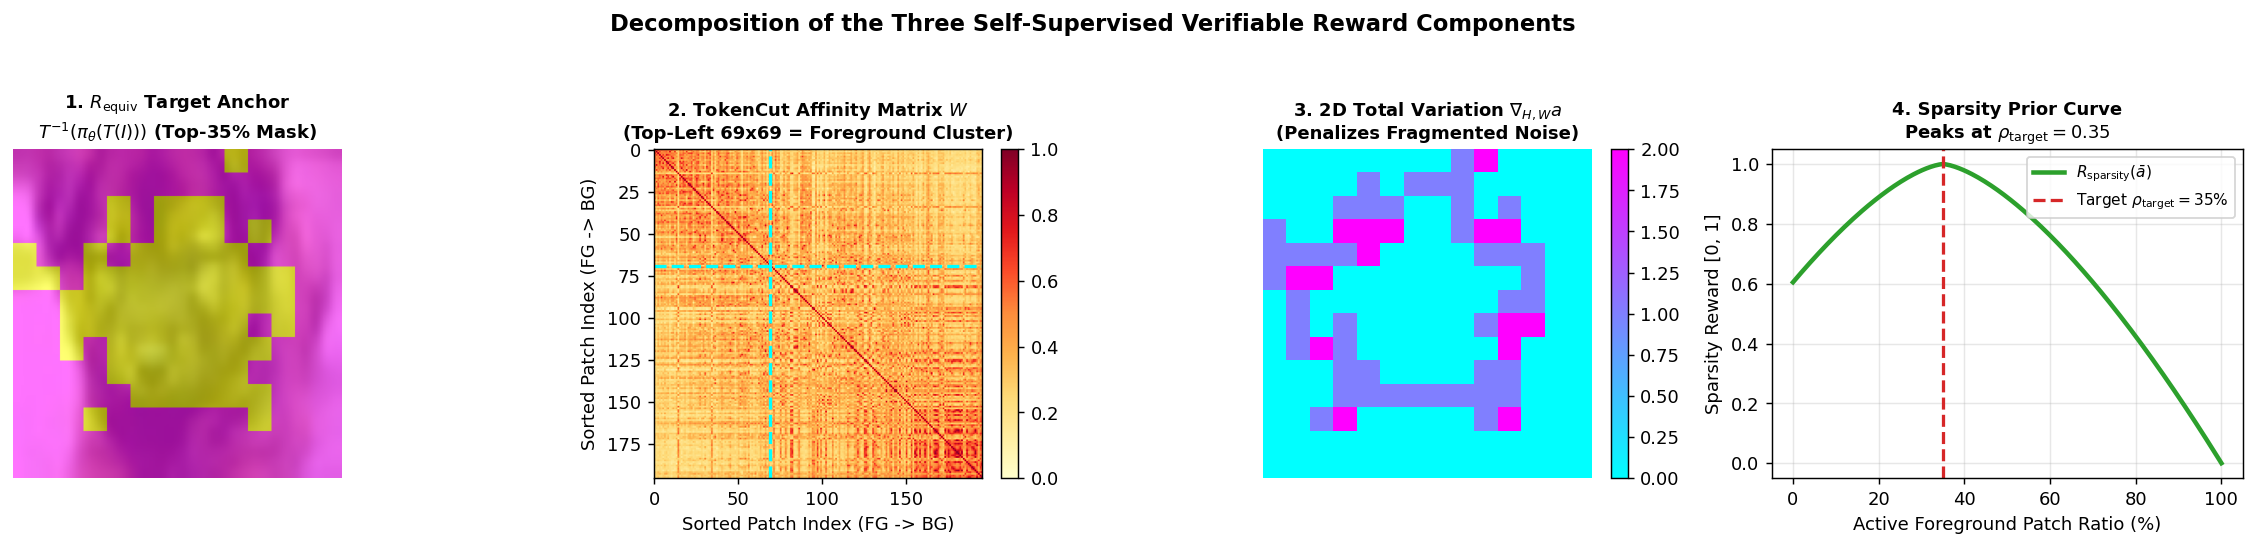

In [3]:
with torch.no_grad():
    k_fg = max(1, int(round(196 * grpo_loss_fn.target_sparsity)))
    topk_idx = torch.topk(equiv_probs, k=k_fg, dim=-1).indices
    eq_binary_mask = torch.zeros_like(equiv_probs).scatter_(-1, topk_idx, 1.0)

    feats_norm = F.normalize(patch_feats.float(), dim=-1, p=2)
    affinity_W = torch.clamp(torch.bmm(feats_norm, feats_norm.transpose(1, 2)), min=0.0)[0].cpu().numpy()

    fg_order = torch.argsort(policy_probs[0], descending=True).cpu().numpy()
    affinity_sorted = affinity_W[fg_order][:, fg_order]

    ratios_grid = np.linspace(0.0, 1.0, 200)
    max_dev = max(0.35, 1.0 - 0.35)
    sparsity_curve = np.clip(1.0 - (np.abs(ratios_grid - 0.35) / max_dev) ** 1.5, 0.0, 1.0)

fig, axes = plt.subplots(1, 4, figsize=(18.0, 4.0))

axes[0].imshow(pil_img)
axes[0].imshow(
    F.interpolate(eq_binary_mask.view(1, 1, 14, 14), size=(224, 224), mode="nearest")[0, 0].cpu().numpy(),
    cmap="spring", alpha=0.55
)
axes[0].set_title("1. $R_{\\mathrm{equiv}}$ Target Anchor\n$T^{-1}(\\pi_\\theta(T(I)))$ (Top-35% Mask)", fontweight="bold", fontsize=10)
axes[0].axis("off")

im_w = axes[1].imshow(affinity_sorted, cmap="YlOrRd", vmin=0.0, vmax=1.0)
axes[1].axvline(k_fg, color="cyan", linestyle="--", linewidth=1.8)
axes[1].axhline(k_fg, color="cyan", linestyle="--", linewidth=1.8)
axes[1].set_title(f"2. TokenCut Affinity Matrix $W$\n(Top-Left {k_fg}x{k_fg} = Foreground Cluster)", fontweight="bold", fontsize=10)
axes[1].set_xlabel("Sorted Patch Index (FG -> BG)")
axes[1].set_ylabel("Sorted Patch Index (FG -> BG)")
plt.colorbar(im_w, ax=axes[1], fraction=0.046, pad=0.04)

p_2d = eq_binary_mask.view(14, 14).cpu().numpy()
tv_map = np.zeros((14, 14))
tv_map[:-1, :] += np.abs(p_2d[1:, :] - p_2d[:-1, :])
tv_map[:, :-1] += np.abs(p_2d[:, 1:] - p_2d[:, :-1])
im_tv = axes[2].imshow(tv_map, cmap="cool")
axes[2].set_title("3. 2D Total Variation $\\nabla_{H,W} a$\n(Penalizes Fragmented Noise)", fontweight="bold", fontsize=10)
axes[2].axis("off")
plt.colorbar(im_tv, ax=axes[2], fraction=0.046, pad=0.04)

axes[3].plot(ratios_grid * 100, sparsity_curve, color="#2ca02c", linewidth=2.5, label="$R_{\\mathrm{sparsity}}(\\bar{a})$")
axes[3].axvline(35.0, color="#d62728", linestyle="--", linewidth=1.8, label="Target $\\rho_{\\mathrm{target}}=35\\%$")
axes[3].set_title("4. Sparsity Prior Curve\nPeaks at $\\rho_{\\mathrm{target}}=0.35$", fontweight="bold", fontsize=10)
axes[3].set_xlabel("Active Foreground Patch Ratio (%)")
axes[3].set_ylabel("Sparsity Reward [0, 1]")
axes[3].grid(True, alpha=0.3)
axes[3].legend(loc="upper right", fontsize=8.5)

plt.suptitle("Decomposition of the Three Self-Supervised Verifiable Reward Components", fontsize=12.5, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

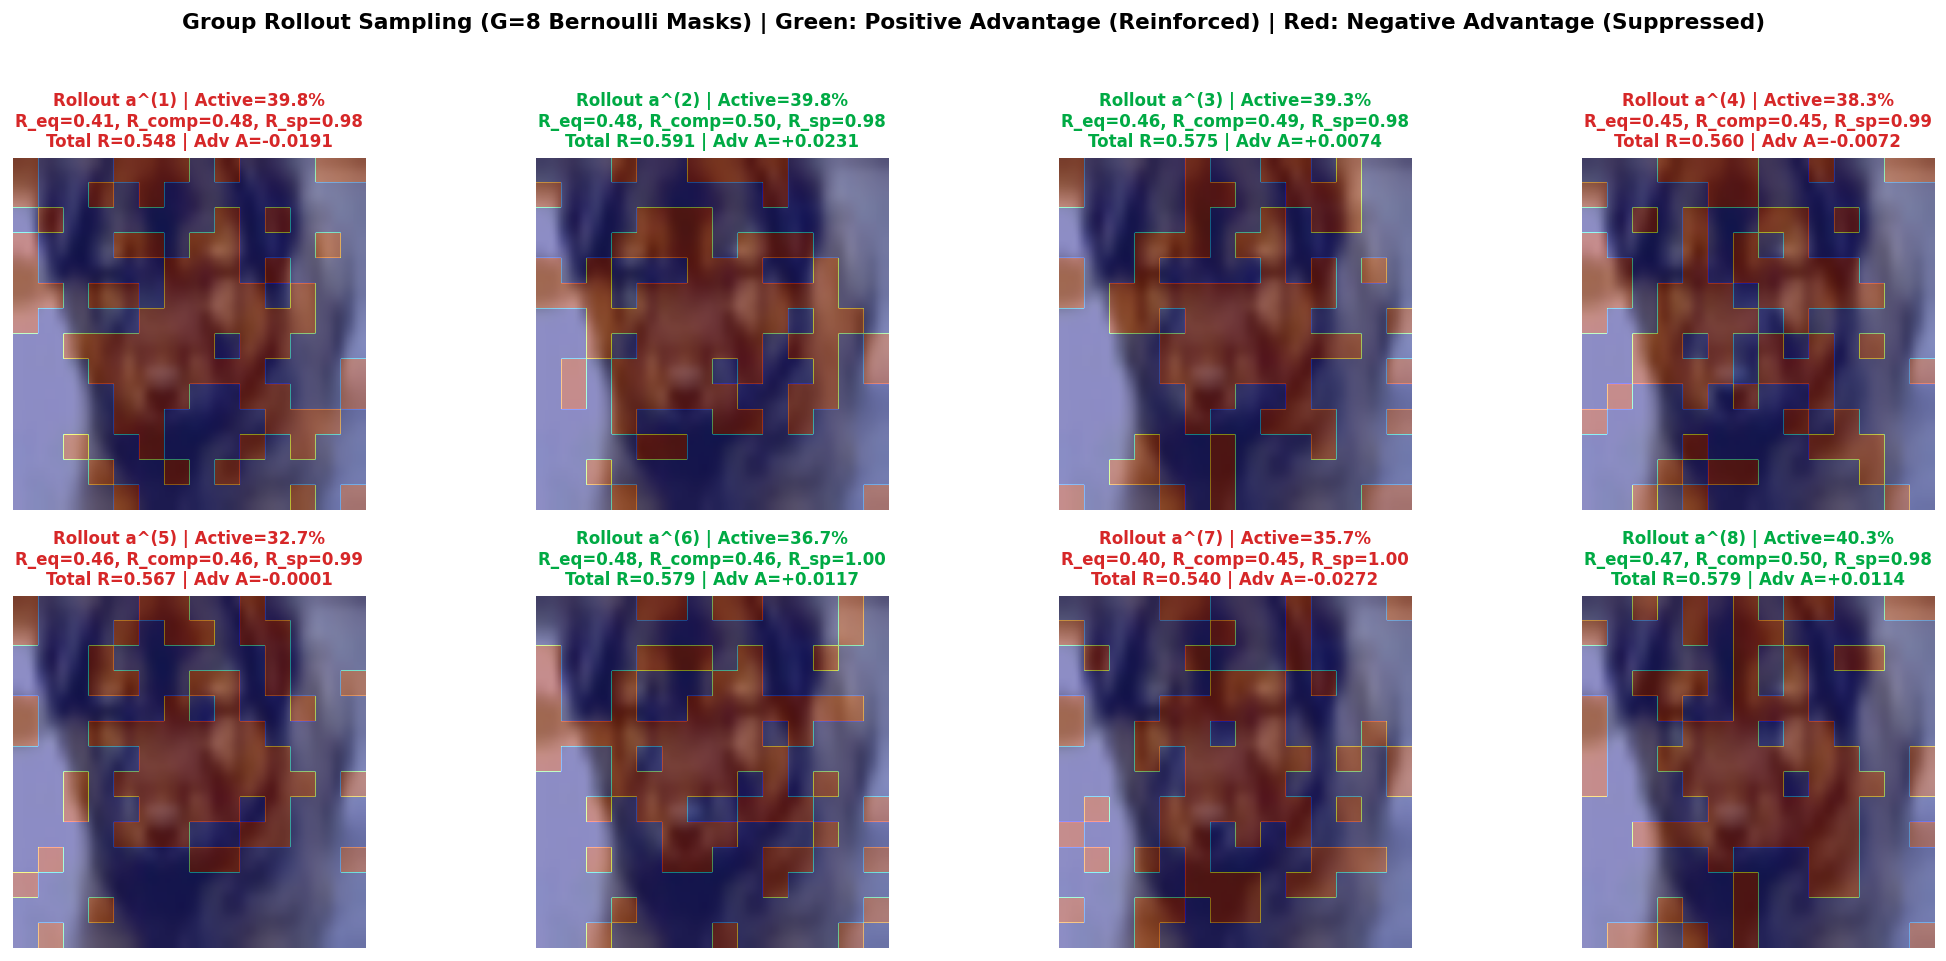

In [4]:
torch.manual_seed(7)
with torch.no_grad():
    explore_probs = 0.55 * policy_probs + 0.45 * ref_probs
    actions, old_log_probs = grpo_loss_fn.sample_actions(explore_probs, group_size=8)

    acts = actions.float()
    r_equiv_vec = grpo_loss_fn._compute_binary_or_soft_iou(acts, eq_binary_mask.unsqueeze(1))[0]

    wa = torch.matmul(acts, torch.clamp(torch.bmm(feats_norm, feats_norm.transpose(1, 2)), min=0.0))
    assoc_fg = (wa * acts).sum(dim=-1)
    cut_fg_bg = (wa * (1.0 - acts)).sum(dim=-1)
    ncut_score = 0.5 * (((assoc_fg - cut_fg_bg) / (wa.sum(dim=-1) + 1e-6)) + 1.0)
    acts_2d = acts.view(1, 8, 14, 14)
    tv_h = (acts_2d[:, :, 1:, :] - acts_2d[:, :, :-1, :]).abs().mean(dim=(-2, -1))
    tv_w = (acts_2d[:, :, :, 1:] - acts_2d[:, :, :, :-1]).abs().mean(dim=(-2, -1))
    spatial_smooth = 1.0 - 0.5 * (tv_h + tv_w)
    r_compact_vec = (0.65 * ncut_score + 0.35 * spatial_smooth)[0]

    active_ratio_vec = acts.mean(dim=-1)[0]
    r_sparsity_vec = torch.clamp(1.0 - ((active_ratio_vec - 0.35).abs() / 0.65) ** 1.5, min=0.0, max=1.0)

    total_r_vec = 0.45 * r_equiv_vec + 0.35 * r_compact_vec + 0.20 * r_sparsity_vec
    adv_dr_grpo = total_r_vec - total_r_vec.mean()

fig, axes = plt.subplots(2, 4, figsize=(16.5, 7.2))
for g in range(8):
    ax = axes[g // 4, g % 4]
    mask_up = F.interpolate(acts[:, g : g + 1].view(1, 1, 14, 14), size=(224, 224), mode="nearest")[0, 0].cpu().numpy()
    ax.imshow(pil_img)
    ax.imshow(mask_up, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    adv_val = adv_dr_grpo[g].item()
    border_col = "#00aa44" if adv_val >= 0 else "#d62728"
    sign_str = "+" if adv_val >= 0 else ""
    ax.set_title(
        f"Rollout a^({g+1}) | Active={active_ratio_vec[g].item()*100:.1f}%\n"
        f"R_eq={r_equiv_vec[g]:.2f}, R_comp={r_compact_vec[g]:.2f}, R_sp={r_sparsity_vec[g]:.2f}\n"
        f"Total R={total_r_vec[g]:.3f} | Adv A={sign_str}{adv_val:.4f}",
        fontsize=9.2, fontweight="bold", color=border_col
    )
    ax.axis("off")

plt.suptitle("Group Rollout Sampling (G=8 Bernoulli Masks) | Green: Positive Advantage (Reinforced) | Red: Negative Advantage (Suppressed)", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 3. Group-Relative Advantage Estimation and Asymmetric Surrogate Clipping
From the group reward vector $\mathbf{R} = [R^{(1)}, \dots, R^{(G)}]^\top$:
1. **Unbiased Dr. GRPO Advantage** (mean-centered without standard-deviation normalization $\sigma_R$ to prevent gradient explosion when rollouts converge):
   $$A_i^{\text{Dr.GRPO}} = R^{(i)} - \frac{1}{G}\sum_{j=1}^G R^{(j)}$$
2. **Rank-Normalized GRPO Advantage (`rank_grpo`)**:
   $$A_i^{\text{rank}} = 2 \cdot \frac{\text{rank}(R^{(i)})}{G - 1} - 1 \in [-1, 1]$$
3. **Length-Normalized Surrogate Objective with DAPO Clip-Higher ($\epsilon_{\text{low}}=0.20, \epsilon_{\text{high}}=0.28$) and Analytical Bernoulli KL**:
   $$\rho_i(\theta) = \exp\!\left(\frac{1}{N}\sum_{p=1}^N \log \frac{\pi_\theta(a_{i,p}|I)}{\pi_{\text{old}}(a_{i,p}|I)}\right)$$
   $$\mathcal{L}_{\text{Dr.GRPO}}(\theta) = -\frac{1}{G}\sum_{i=1}^G \min\!\Big(\rho_i(\theta) A_i,\; \text{clip}(\rho_i(\theta),\, 1 - \epsilon_{\text{low}},\, 1 + \epsilon_{\text{high}}) A_i\Big) + \beta_{\text{KL}}\, D_{\text{KL}}\!\big(\pi_\theta \,\|\, \pi_{\text{ref}}\big)$$

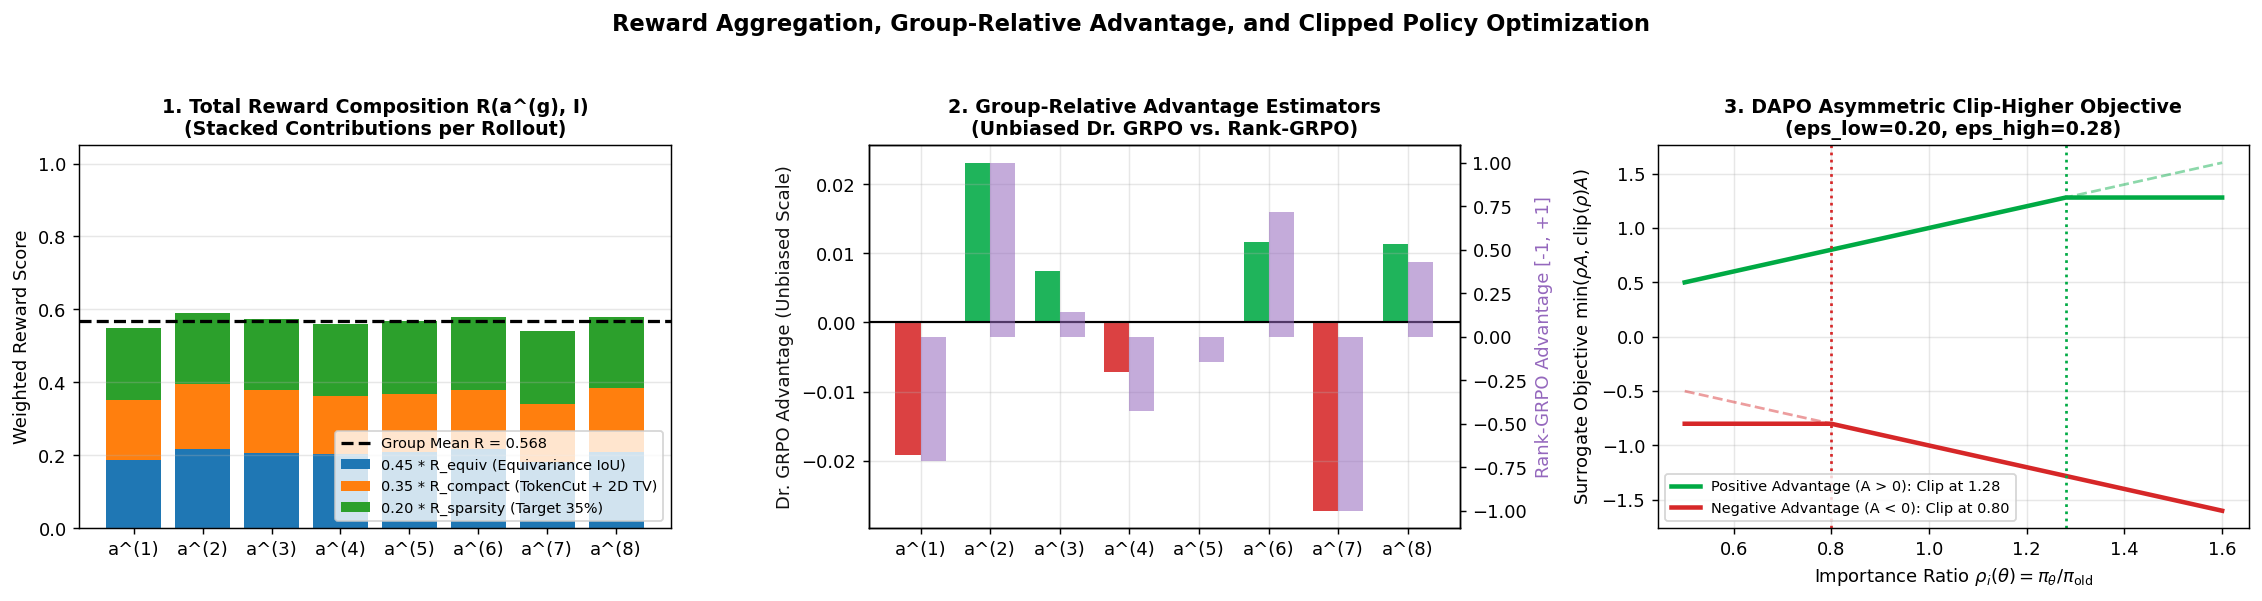

In [5]:
rollout_ids = [f"a^({g+1})" for g in range(8)]
c_eq = (0.45 * r_equiv_vec).cpu().numpy()
c_comp = (0.35 * r_compact_vec).cpu().numpy()
c_spar = (0.20 * r_sparsity_vec).cpu().numpy()
tot_r = total_r_vec.cpu().numpy()

ranks = torch.argsort(torch.argsort(total_r_vec)).float()
adv_rank = (2.0 * (ranks / 7.0) - 1.0).cpu().numpy()
adv_dr = adv_dr_grpo.cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.4))

x_pos = np.arange(8)
axes[0].bar(x_pos, c_eq, color="#1f77b4", label="0.45 * R_equiv (Equivariance IoU)")
axes[0].bar(x_pos, c_comp, bottom=c_eq, color="#ff7f0e", label="0.35 * R_compact (TokenCut + 2D TV)")
axes[0].bar(x_pos, c_spar, bottom=c_eq + c_comp, color="#2ca02c", label="0.20 * R_sparsity (Target 35%)")
axes[0].axhline(tot_r.mean(), color="black", linestyle="--", linewidth=1.8, label=f"Group Mean R = {tot_r.mean():.3f}")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(rollout_ids)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("1. Total Reward Composition R(a^(g), I)\n(Stacked Contributions per Rollout)", fontweight="bold", fontsize=10.5)
axes[0].set_ylabel("Weighted Reward Score")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].grid(True, axis="y", alpha=0.3)

ax1 = axes[1]
ax1_twin = ax1.twinx()
w = 0.36
ax1.bar(x_pos - w/2, adv_dr, width=w, color=["#00aa44" if v >= 0 else "#d62728" for v in adv_dr], alpha=0.88, label="Dr. GRPO: A_i = R_i - mean(R)")
ax1_twin.bar(x_pos + w/2, adv_rank, width=w, color="#9467bd", alpha=0.55, label="Rank-GRPO: A_i in [-1, 1]")
ax1.axhline(0.0, color="black", linewidth=1.2)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(rollout_ids)
ax1.set_title("2. Group-Relative Advantage Estimators\n(Unbiased Dr. GRPO vs. Rank-GRPO)", fontweight="bold", fontsize=10.5)
ax1.set_ylabel("Dr. GRPO Advantage (Unbiased Scale)", color="#111111")
ax1_twin.set_ylabel("Rank-GRPO Advantage [-1, +1]", color="#9467bd")
ax1.grid(True, alpha=0.3)

rho_grid = np.linspace(0.5, 1.6, 300)
surr_pos_unclipped = rho_grid * 1.0
surr_pos_clipped = np.minimum(rho_grid * 1.0, np.clip(rho_grid, 1.0 - 0.20, 1.0 + 0.28) * 1.0)
surr_neg_unclipped = rho_grid * (-1.0)
surr_neg_clipped = np.minimum(rho_grid * (-1.0), np.clip(rho_grid, 1.0 - 0.20, 1.0 + 0.28) * (-1.0))

axes[2].plot(rho_grid, surr_pos_unclipped, "--", color="#00aa44", alpha=0.45)
axes[2].plot(rho_grid, surr_pos_clipped, "-", color="#00aa44", linewidth=2.5, label="Positive Advantage (A > 0): Clip at 1.28")
axes[2].plot(rho_grid, surr_neg_unclipped, "--", color="#d62728", alpha=0.45)
axes[2].plot(rho_grid, surr_neg_clipped, "-", color="#d62728", linewidth=2.5, label="Negative Advantage (A < 0): Clip at 0.80")
axes[2].axvline(0.80, color="#d62728", linestyle=":", linewidth=1.5)
axes[2].axvline(1.28, color="#00aa44", linestyle=":", linewidth=1.5)
axes[2].set_title("3. DAPO Asymmetric Clip-Higher Objective\n(eps_low=0.20, eps_high=0.28)", fontweight="bold", fontsize=10.5)
axes[2].set_xlabel("Importance Ratio $\\rho_i(\\theta) = \\pi_\\theta / \\pi_{\\mathrm{old}}$")
axes[2].set_ylabel("Surrogate Objective $\\min(\\rho A, \\mathrm{clip}(\\rho) A)$")
axes[2].legend(loc="lower left", fontsize=8)
axes[2].grid(True, alpha=0.3)

plt.suptitle("Reward Aggregation, Group-Relative Advantage, and Clipped Policy Optimization", fontsize=12.5, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()